In [197]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_curve, auc, confusion_matrix
from sklearn.preprocessing import label_binarize



In [198]:
# Load CSV file
df = pd.read_csv("Dataset_2024.csv")

# Remove spaces before column names
df.columns = df.columns.str.strip()



In [199]:
# Check unique values in the 'Label' column
print(df['Label'].unique())




[0 1]


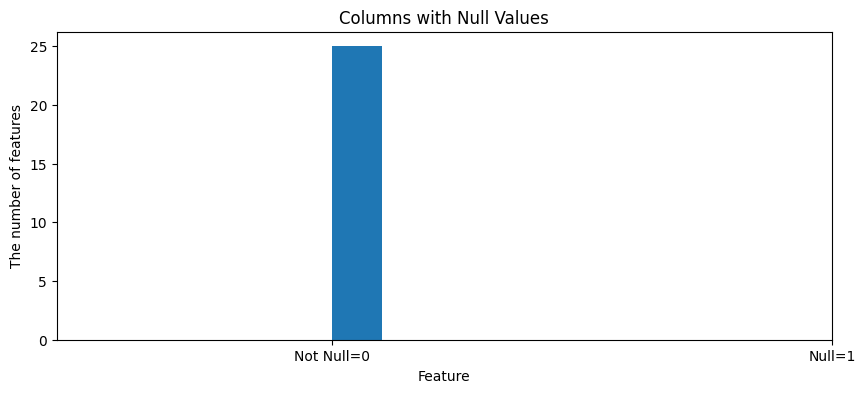

In [200]:
# Plot null values as histogram
plt.figure(1, figsize=(10, 4))
plt.hist(df.isna().sum())
plt.xticks([0, 1], labels=['Not Null=0', 'Null=1'])
plt.title('Columns with Null Values')
plt.xlabel('Feature')
plt.ylabel('The number of features')
plt.show()



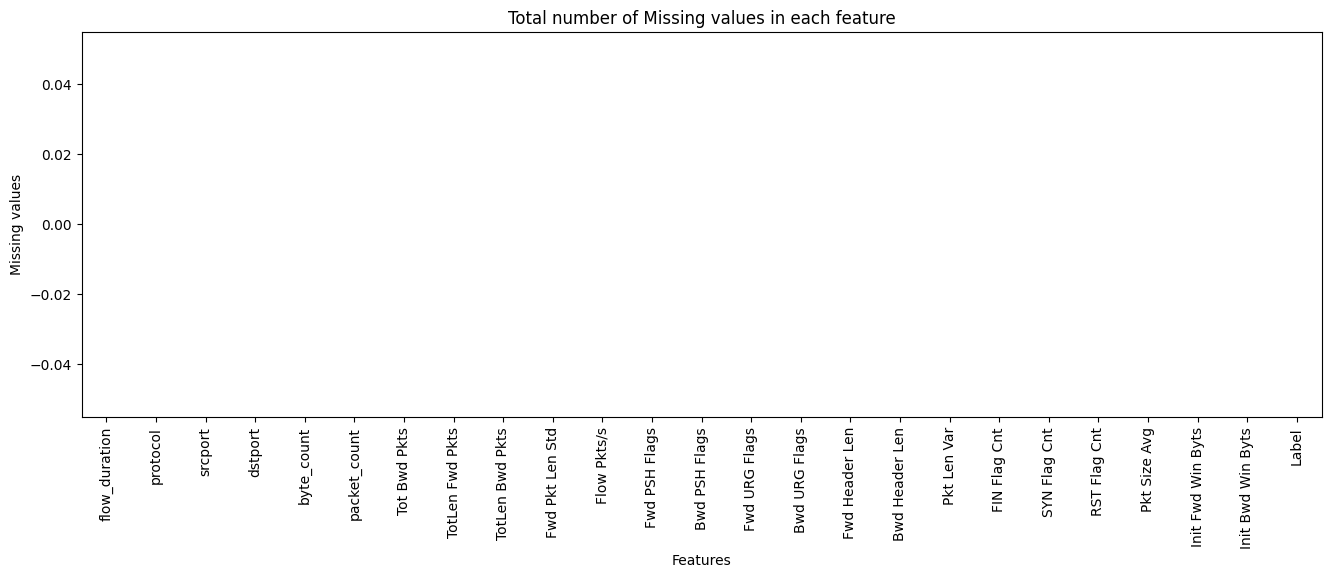

In [201]:
# Function to plot missing values
def plotMissingValues(dataframe):
    missing_values = dataframe.isnull().sum()
    fig = plt.figure(figsize=(16, 5))
    missing_values.plot(kind='bar')
    plt.xlabel("Features")
    plt.ylabel("Missing values")
    plt.title("Total number of Missing values in each feature")
    plt.show()

plotMissingValues(df)




In [202]:
# Remove null values
data_f = df.dropna()



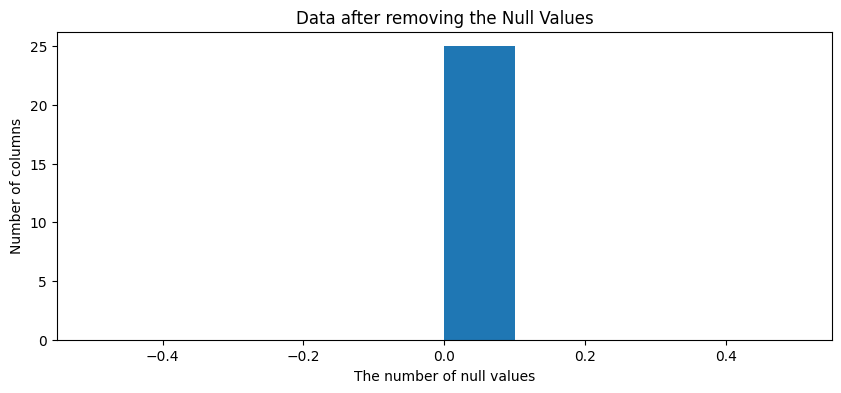

In [203]:
# Plot after removing null values
plt.figure(1, figsize=(10, 4))
plt.hist(data_f.isna().sum())
plt.title('Data after removing the Null Values')
plt.xlabel('The number of null values')
plt.ylabel('Number of columns')
plt.show()



In [204]:
# Replace inf and -inf with NaN
data_f = data_f.replace([np.inf, -np.inf], np.nan)



In [205]:
# Check for NaN and inf values
print(data_f['Label'].isnull().sum())  # Check for NaN values
print(np.isinf(data_f['Label']).sum())  # Check for inf values

# Handle NaN and inf values in 'Label' column
data_f = data_f[~data_f['Label'].isnull()]  # Remove NaN
data_f = data_f[~np.isinf(data_f['Label'])]  # Remove inf



0
0


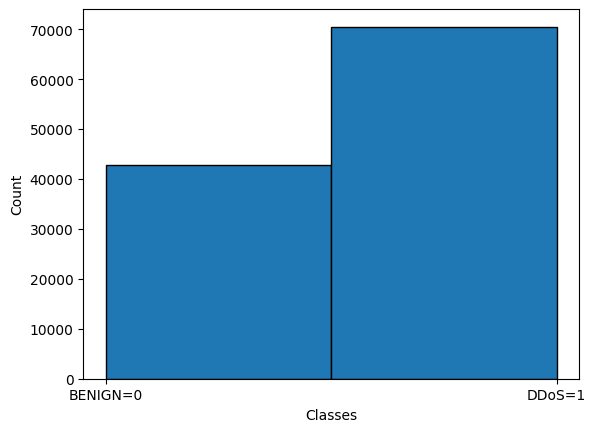

In [206]:
# Plot the histogram
plt.hist(data_f['Label'], bins=2, edgecolor='black')
plt.xticks([0, 1], labels=['BENIGN=0', 'DDoS=1'])
plt.xlabel("Classes")
plt.ylabel("Count")
plt.show()

In [207]:
print(df.describe())

       flow_duration       protocol        srcport        dstport  \
count   1.134070e+05  113407.000000  113407.000000  113407.000000   
mean    5.675157e+06       4.205825   13404.874496    3942.364598   
std     2.290923e+07       6.446244   21656.132359   13247.903299   
min    -1.540000e+02       0.000000       0.000000       0.000000   
25%     1.700000e+01       0.000000       0.000000       0.000000   
50%     3.600000e+01       0.000000       0.000000       0.000000   
75%     3.325000e+03       6.000000   36313.000000      53.000000   
max     1.200000e+08      17.000000   65513.000000   60994.000000   

         byte_count   packet_count   Tot Bwd Pkts  TotLen Fwd Pkts  \
count  1.134070e+05  113407.000000  113407.000000     1.134070e+05   
mean   3.149522e+05     138.744257       8.995829     1.607594e+03   
std    8.064643e+06    1847.267425     156.940094     1.211427e+05   
min    0.000000e+00       0.000000       1.000000     0.000000e+00   
25%    0.000000e+00       0.

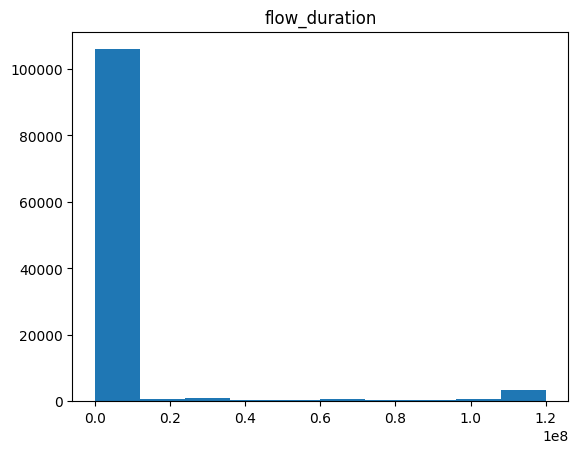

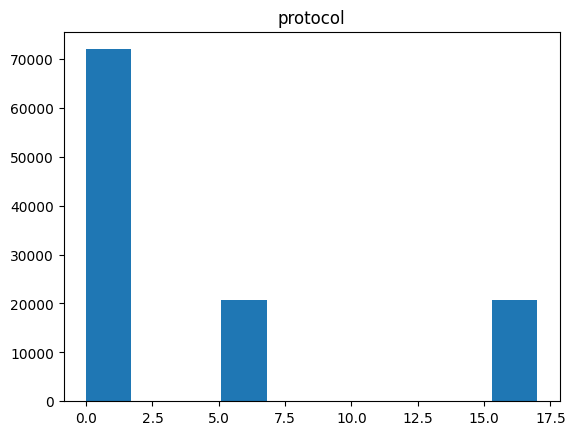

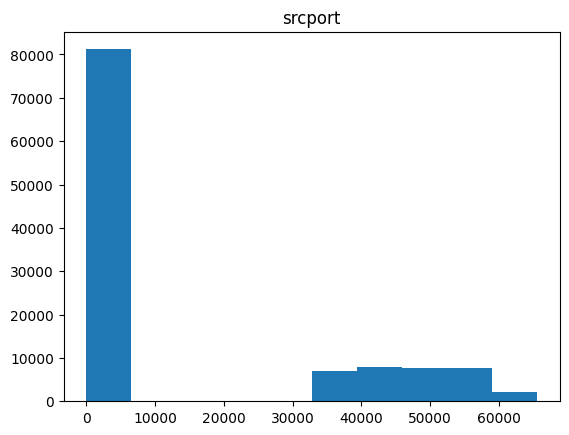

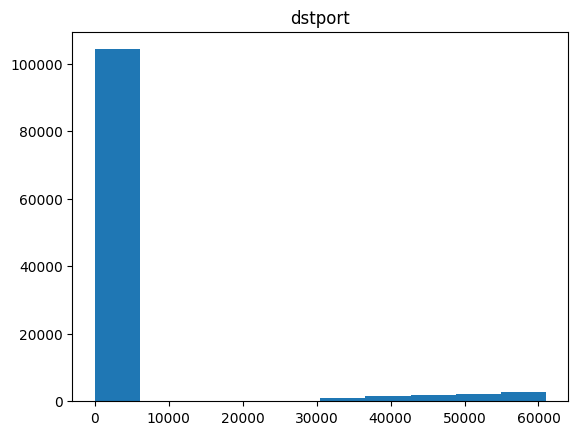

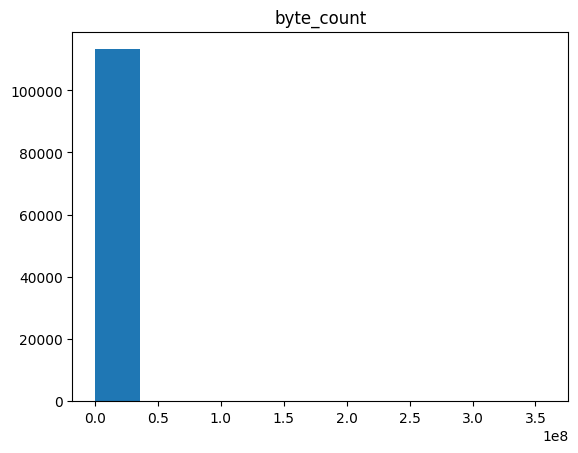

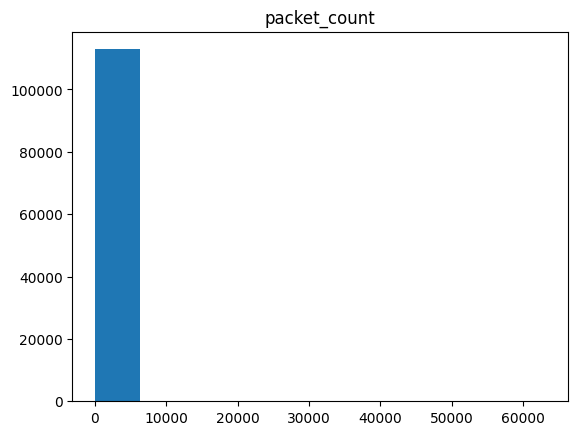

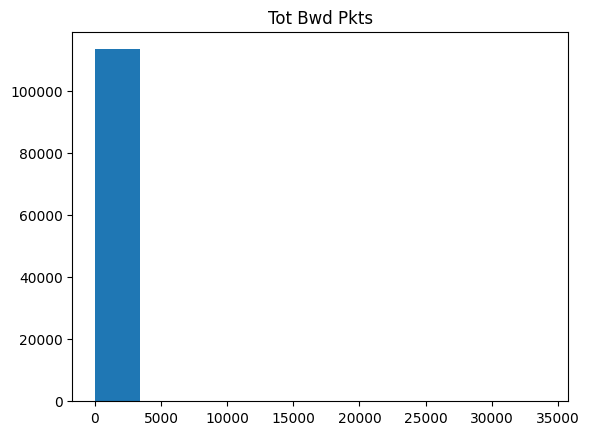

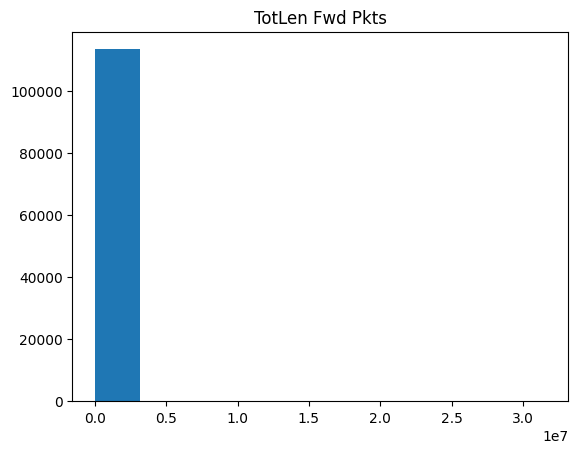

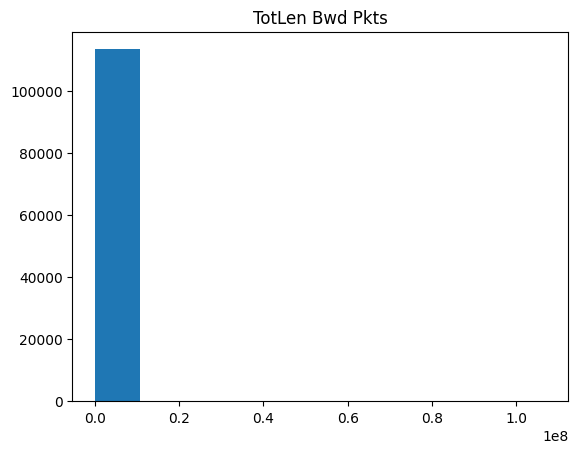

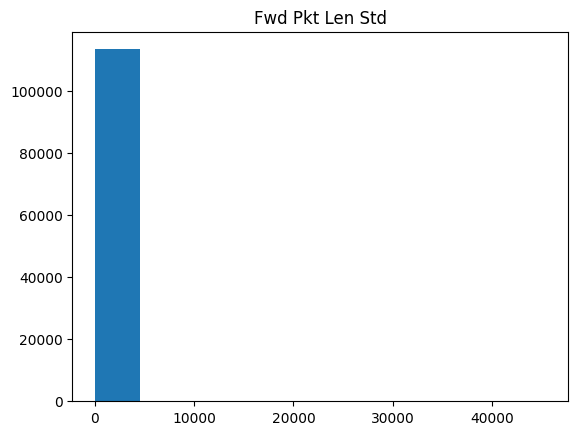

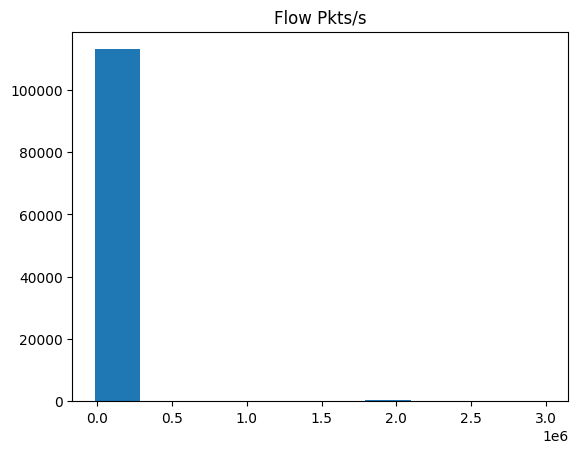

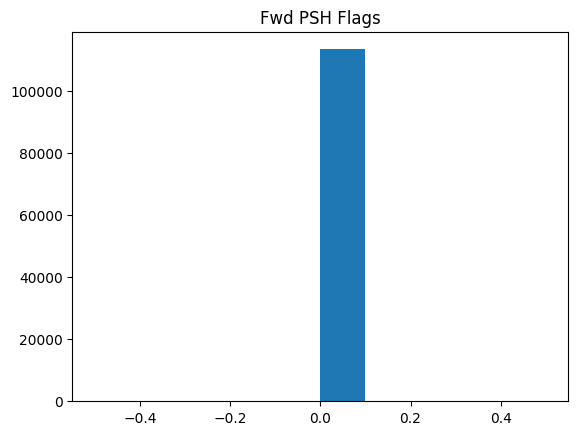

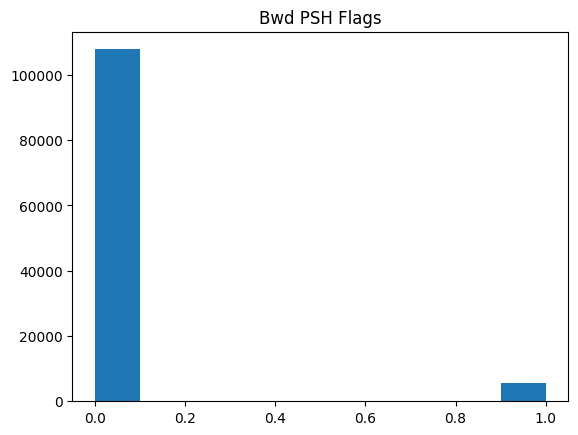

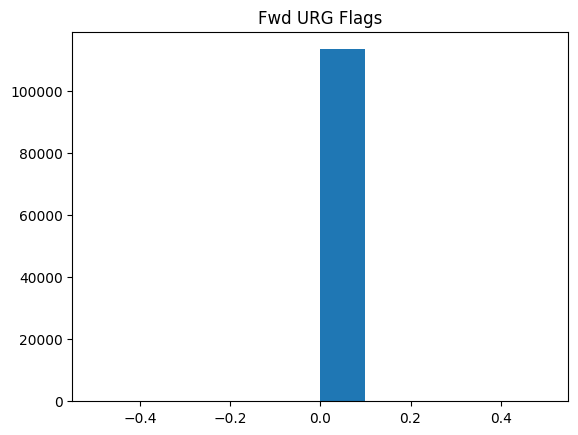

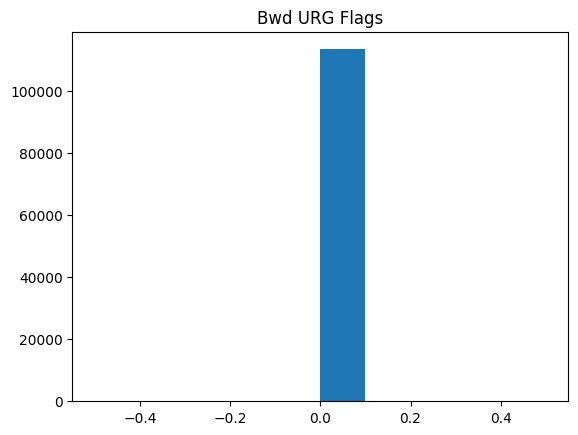

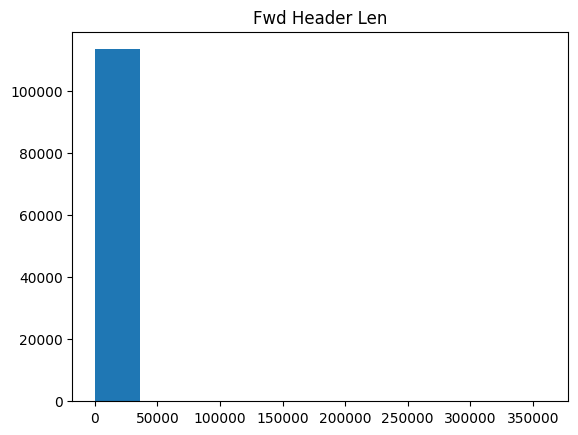

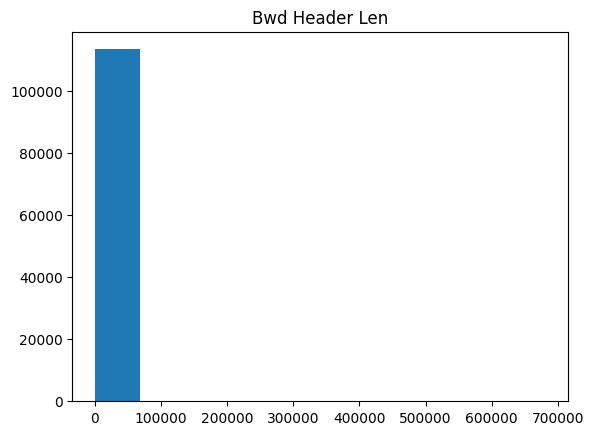

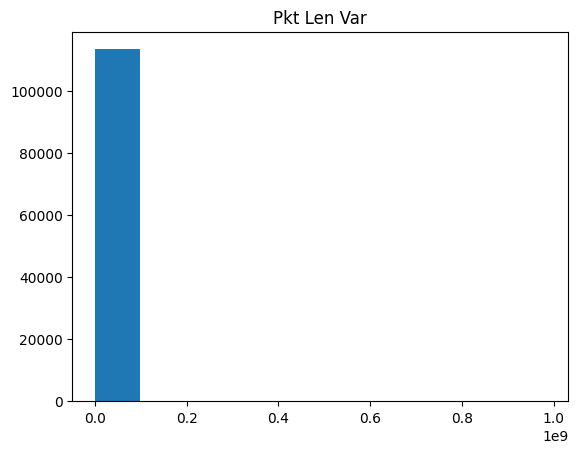

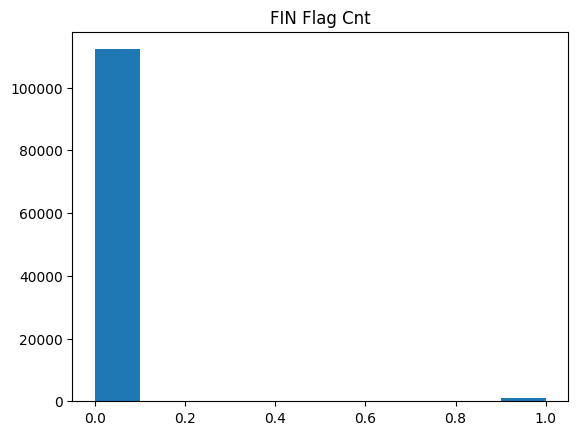

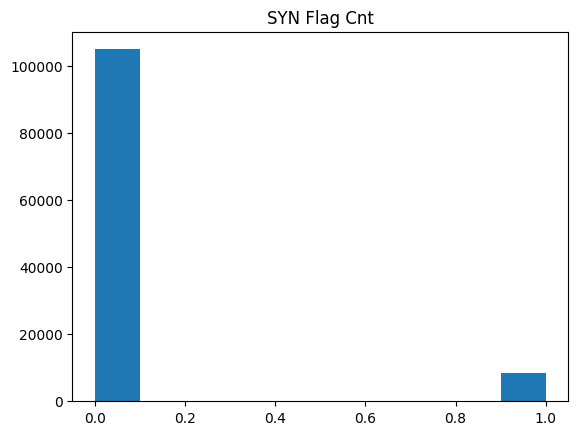

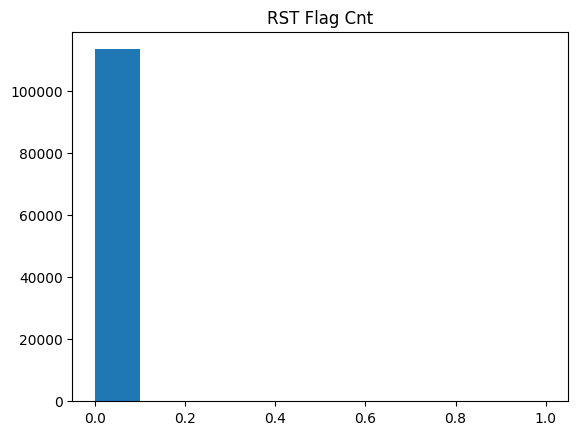

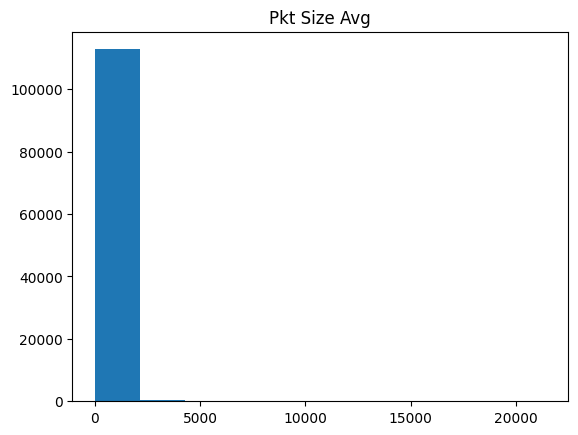

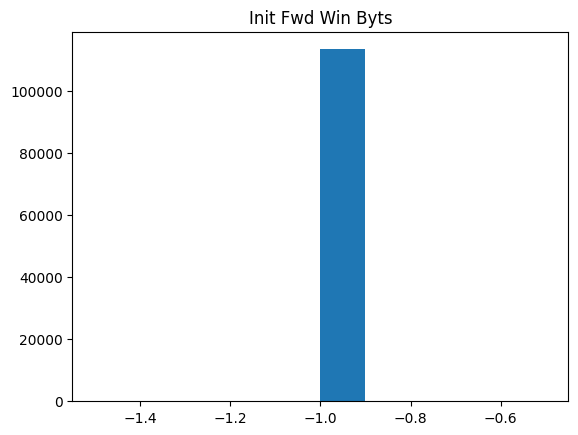

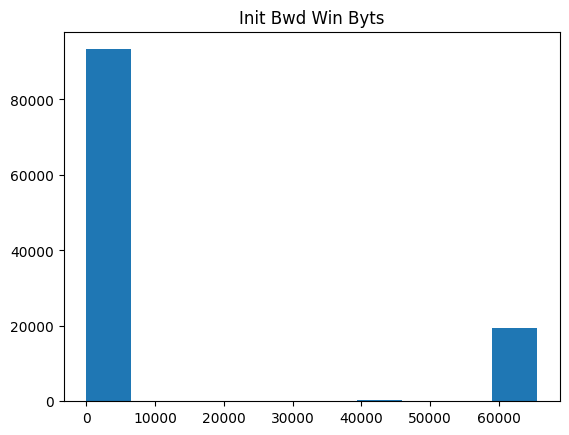

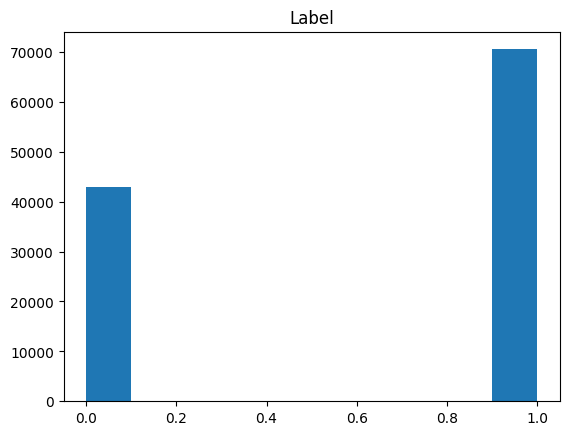

In [208]:
# plt.figure(figsize=(15, 10))  # Optional: Set figure size
# for col in data_f.columns:
#     plt.figure()  # Create a new figure for each histogram
#     plt.hist(data_f[col].dropna())  # Drop NaN values for plotting
#     plt.title(col)
#     plt.xlabel('Value')
#     plt.ylabel('Frequency')
#     plt.show()

# Create a histogram plot for each feature
plt.figure(5)
for col in data_f.columns:
    if data_f[col].isnull().sum() == len(data_f[col]):
        print(f"Skipping {col} because it has all NaN values.")
        continue
    plt.hist(data_f[col].dropna())  # Use dropna() to avoid NaN issues
    plt.title(col)
    plt.show()


In [209]:
# Convert into numpy array

#X1=np.array(data_f).astype(np.float64)
#y1=np.array(data_f['Label'])



In [210]:
# Split data into features and target variable
X = data_f.drop('Label', axis=1)
y = data_f['Label']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

In [211]:
print("The train dataset size = ",X_train.shape)
print("The test dataset size = ",X_test.shape)

The train dataset size =  (79384, 24)
The test dataset size =  (34023, 24)


---

# Training the Model

---


### Random Forest 

In [212]:
# Random Forest
rf_model = RandomForestClassifier(n_estimators=50, random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

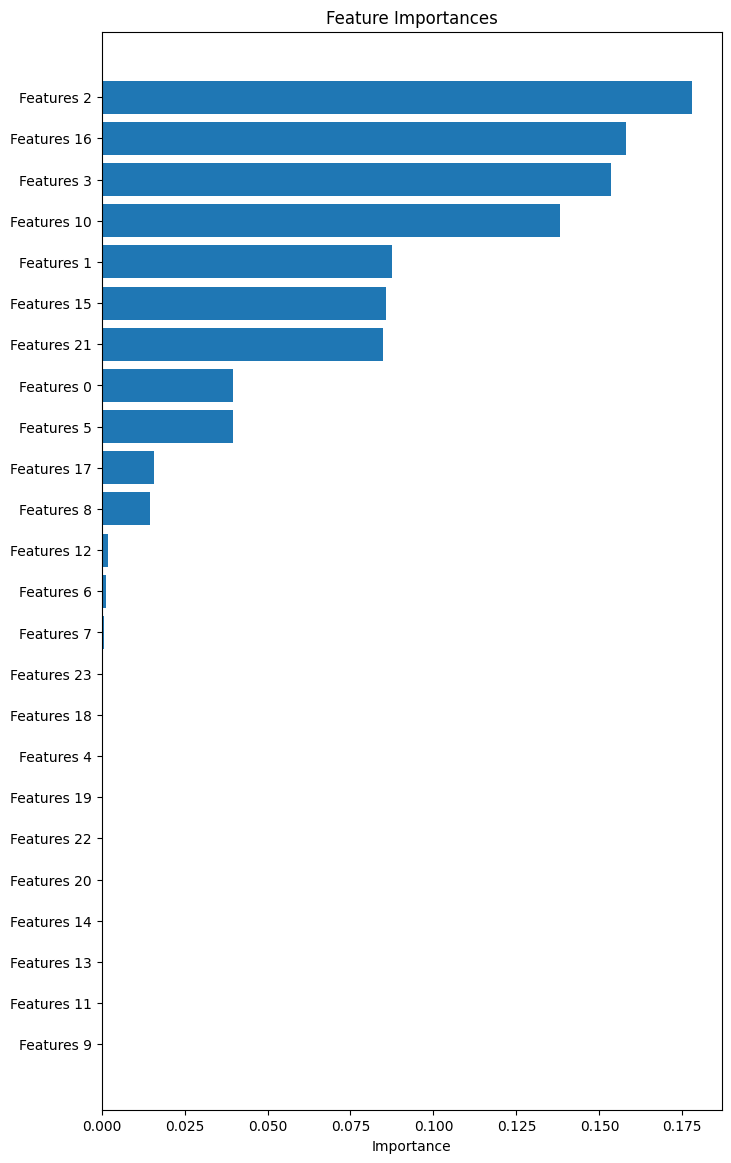

In [213]:
# Getting feature importances from the trained model
importances = rf_model.feature_importances_

# Getting the indices of features sorted by importance
indices = sorted(range(len(importances)), key=lambda i: importances[i], reverse=False)
feature_names = [f"Features {i}" for i in indices]  # Replace with your column names

# Plotting feature importances horizontally
plt.figure(figsize=(8, 14))
plt.barh(range(X_train.shape[1]), importances[indices], align="center")
plt.yticks(range(X_train.shape[1]), feature_names)
plt.xlabel("Importance")
plt.title("Feature Importances")
plt.show()

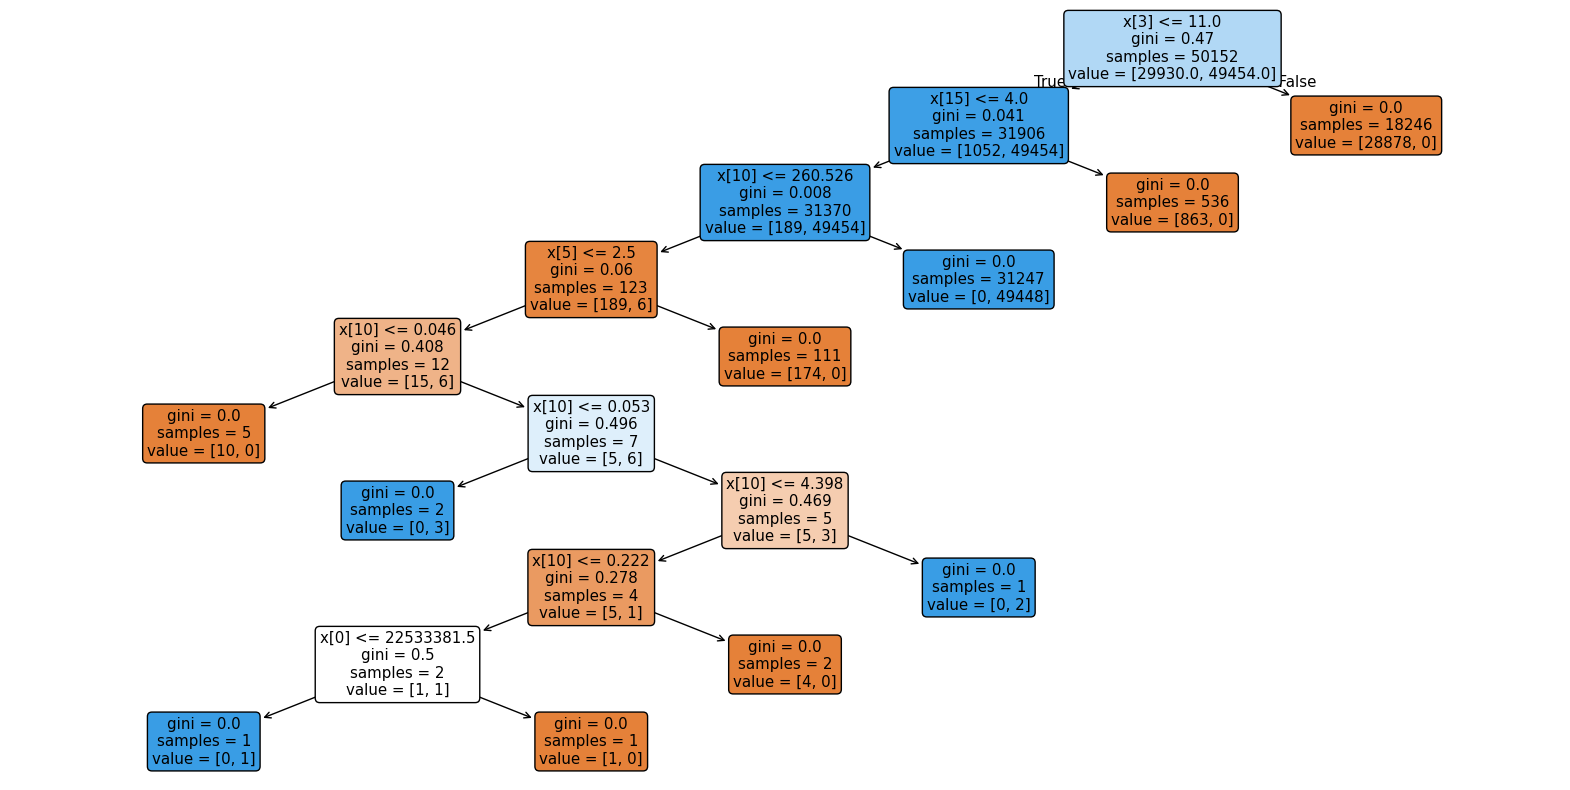

In [214]:
from sklearn.tree import plot_tree

estimator = rf_model.estimators_[0]  # Selecting the first estimator from the random forest model


plt.figure(figsize=(20, 10))
plot_tree(estimator, filled=True, rounded=True)
plt.show()

### Model Evaluation 

In [215]:
# Function to generate and display a detailed confusion matrix
def plot_confusion_matrix(y_true, y_pred, classes, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
    plt.title(title)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()

In [216]:
# Evaluate Random Forest
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)

print('\nRandom Forest Metrics:')
print(f'Accuracy: {rf_accuracy:.4f}')
print(f'F1 Score: {rf_f1:.4f}')
print(f'Precision: {rf_precision:.4f}')
print(f'Recall: {rf_recall:.4f}')



Random Forest Metrics:
Accuracy: 0.9999
F1 Score: 1.0000
Precision: 1.0000
Recall: 0.9999


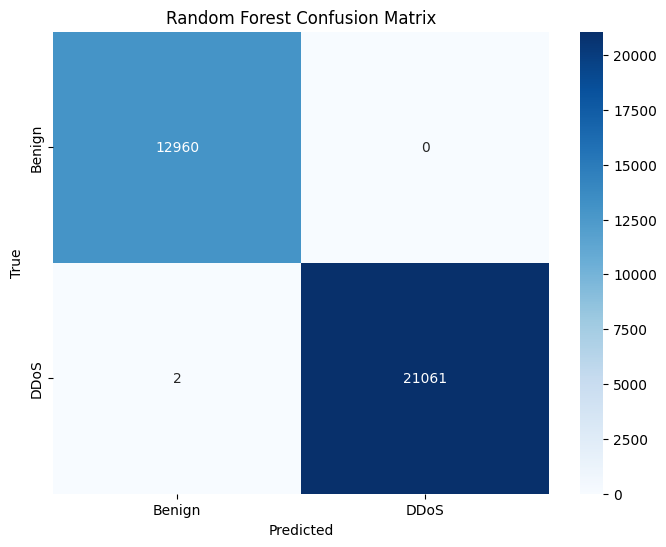

In [217]:
# Confusion Matrix for Random Forest
plot_confusion_matrix(y_test, rf_pred, ['Benign', 'DDoS'], 'Random Forest Confusion Matrix')

### Logistic Regression

In [218]:
# Scale the features (important for Logistic Regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Logistic Regression with increased max_iter and scaled features
lr_model = LogisticRegression(random_state=42, max_iter=200)  # Increase max_iter
lr_model.fit(X_train_scaled, y_train)  # Fit on scaled data
lr_pred = lr_model.predict(X_test_scaled)  # Predict on scaled data


### Evaluate Logistic Regression

In [219]:

lr_accuracy = accuracy_score(y_test, lr_pred)
lr_f1 = f1_score(y_test, lr_pred)
lr_precision = precision_score(y_test, lr_pred)
lr_recall = recall_score(y_test, lr_pred)

In [220]:
print('\nLogistic Regression Metrics:')
print(f'Accuracy: {lr_accuracy:.4f}')
print(f'F1 Score: {lr_f1:.4f}')
print(f'Precision: {lr_precision:.4f}')
print(f'Recall: {lr_recall:.4f}')



Logistic Regression Metrics:
Accuracy: 0.9990
F1 Score: 0.9992
Precision: 0.9985
Recall: 0.9999


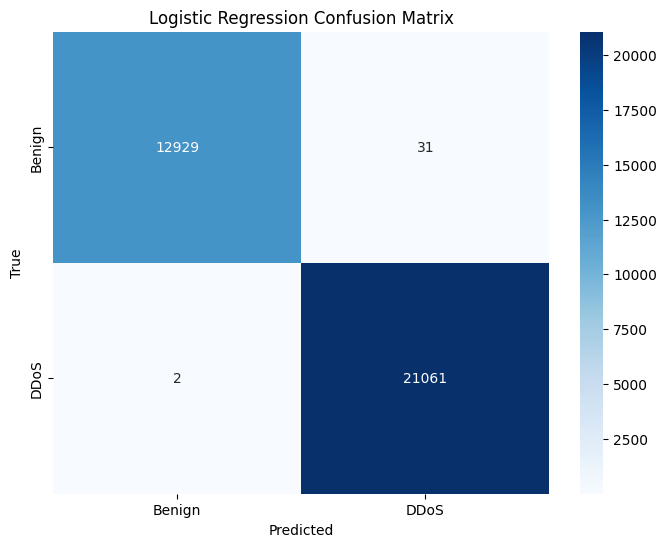

In [221]:
# Confusion Matrix for Logistic Regression
plot_confusion_matrix(y_test, lr_pred, ['Benign', 'DDoS'], 'Logistic Regression Confusion Matrix')


### Neural Network

In [222]:
# Scale the features and keep column names
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

# Train the models
rf_model.fit(X_train_scaled, y_train)
lr_model.fit(X_train_scaled, y_train)
nn_model.fit(X_train_scaled, y_train)

# Make predictions with the trained models
rf_proba = rf_model.predict_proba(X_test_scaled)
lr_proba = lr_model.predict_proba(X_test_scaled)
nn_proba = nn_model.predict_proba(X_test_scaled)


Iteration 1, loss = 0.16227064
Iteration 2, loss = 0.01474119
Iteration 3, loss = 0.00718770
Iteration 4, loss = 0.00510899
Iteration 5, loss = 0.00420697
Iteration 6, loss = 0.00369687
Iteration 7, loss = 0.00336824
Iteration 8, loss = 0.00310784
Iteration 9, loss = 0.00290632
Iteration 10, loss = 0.00273072
Iteration 11, loss = 0.00258347
Iteration 12, loss = 0.00246099
Iteration 13, loss = 0.00232141
Iteration 14, loss = 0.00220421
Iteration 15, loss = 0.00209958
Iteration 16, loss = 0.00200326
Iteration 17, loss = 0.00193398
Iteration 18, loss = 0.00185344
Iteration 19, loss = 0.00178928
Iteration 20, loss = 0.00174404
Iteration 21, loss = 0.00168260
Iteration 22, loss = 0.00164155
Iteration 23, loss = 0.00161336
Iteration 24, loss = 0.00158563
Iteration 25, loss = 0.00155260
Iteration 26, loss = 0.00151290
Training loss did not improve more than tol=0.000100 for 10 consecutive epochs. Stopping.


### # Evaluate Neural Network

In [223]:
nn_accuracy = accuracy_score(y_test, nn_pred)
nn_f1 = f1_score(y_test, nn_pred)
nn_precision = precision_score(y_test, nn_pred)
nn_recall = recall_score(y_test, nn_pred)

print('\nNeural Network Metrics:')
print(f'Accuracy: {nn_accuracy:.4f}')
print(f'F1 Score: {nn_f1:.4f}')
print(f'Precision: {nn_precision:.4f}')
print(f'Recall: {nn_recall:.4f}')


Neural Network Metrics:
Accuracy: 0.9993
F1 Score: 0.9994
Precision: 0.9990
Recall: 0.9998


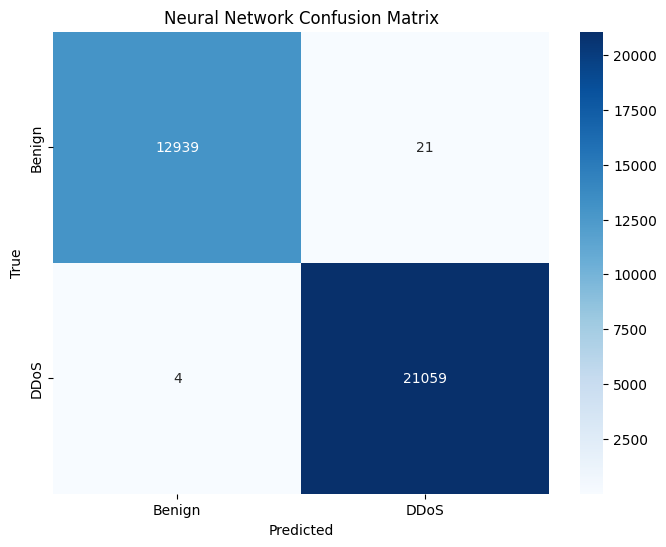

In [224]:
# Confusion Matrix for Neural Network
plot_confusion_matrix(y_test, nn_pred, ['Benign', 'DDoS'], 'Neural Network Confusion Matrix')

## Model Comparison

In [225]:
# Random Forest
rf_proba = rf_model.predict_proba(X_test)

# Logistic Regression
lr_proba = lr_model.predict_proba(X_test)



# Neural Network
nn_proba = nn_model.predict_proba(X_test)

In [226]:
# Combine predictions for ROC curve



# Calculate ROC curve for Random Forest
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_proba[:, 1])
rf_auc = auc(rf_fpr, rf_tpr)

# Calculate ROC curve for Logistic Regression
lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_proba[:, 1])
lr_auc = auc(lr_fpr, lr_tpr)



# Calculate ROC curve for Neural Network
nn_fpr, nn_tpr, _ = roc_curve(y_test, nn_proba[:, 1])
nn_auc = auc(nn_fpr, nn_tpr)


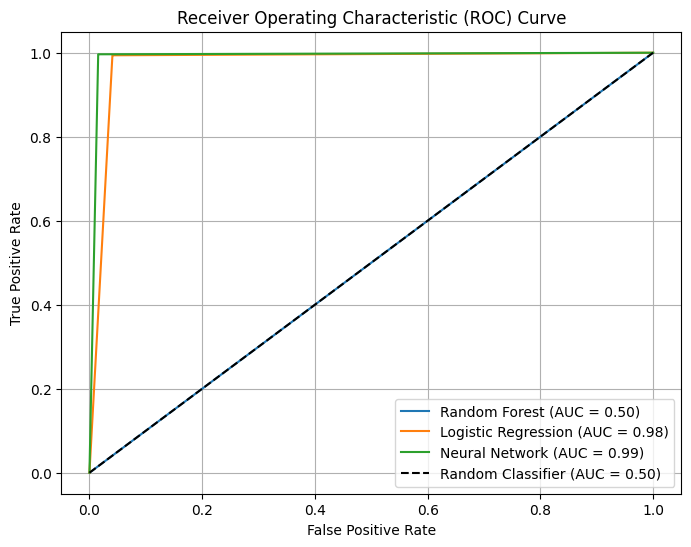

In [227]:
# Plot ROC curves for all models
plt.figure(figsize=(8, 6))
plt.plot(rf_fpr, rf_tpr, label=f'Random Forest (AUC = {rf_auc:.2f})')
plt.plot(lr_fpr, lr_tpr, label=f'Logistic Regression (AUC = {lr_auc:.2f})')
plt.plot(nn_fpr, nn_tpr, label=f'Neural Network (AUC = {nn_auc:.2f})')

# Plot ROC curve for random classifier (50% area)
plt.plot([0, 1], [0, 1], linestyle='--', color='black', label='Random Classifier (AUC = 0.50)')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend()
plt.grid()
plt.show()